In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os, json

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

BASE_DIR        = "/home/23dcs510/Smart-Recommendation-System/brain/"
MODEL_PATH      = BASE_DIR + "neural_interaction_model.pth"
USER_EMB_PATH   = BASE_DIR + "user_embeddings.npy"
USER_IDS_PATH   = BASE_DIR + "user_ids.npy"
POI_EMB_PATH    = BASE_DIR + "poi_embeddings_262.npy"
POI_IDS_PATH    = BASE_DIR + "poi_ids_262.npy"
MEMBERSHIP_PATH = BASE_DIR + "poi_fuzzy_memberships.npy"
CLUSTER_IDS_PATH= BASE_DIR + "poi_cluster_ids.npy"
LABELS_PATH     = BASE_DIR + "poi_aesthetic_labels.csv"
FILTERED_POI    = BASE_DIR + "filtered_poi_ids.npy"
FILTERED_PID    = BASE_DIR + "filtered_photo_ids.npy"
CSV_PATH        = BASE_DIR + "usa_europe_geotagged.csv"
OUTPUT_DIR      = BASE_DIR

K_VALUES        = [5, 10, 20]
EVAL_USERS      = 500    # users to evaluate on
BATCH_SIZE      = 4096

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
print("Loading model and embeddings...")

# Model
class NeuralInteractionLayer(nn.Module):
    def __init__(self, user_dim=262, poi_dim=262):
        super().__init__()
        self.user_tower = nn.Sequential(
            nn.Linear(user_dim, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2)
        )
        self.poi_tower = nn.Sequential(
            nn.Linear(poi_dim, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2)
        )
        self.interaction = nn.Sequential(
            nn.Linear(128*3, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, 128),  nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(128, 64),   nn.GELU(),
            nn.Linear(64, 1),     nn.Sigmoid()
        )
    def forward(self, u, p):
        u  = self.user_tower(u)
        p  = self.poi_tower(p)
        ip = u * p
        return self.interaction(torch.cat([u, p, ip], dim=1)).squeeze(-1)

model = NeuralInteractionLayer().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()
print("✓ Model loaded")

# Embeddings
user_embeddings = np.load(USER_EMB_PATH).astype(np.float32)
user_ids        = np.load(USER_IDS_PATH, allow_pickle=True)
poi_embeddings  = np.load(POI_EMB_PATH).astype(np.float32)
poi_ids         = np.load(POI_IDS_PATH)
poi_labels_df   = pd.read_csv(LABELS_PATH)
filtered_pois   = np.load(FILTERED_POI)
filtered_pids   = np.load(FILTERED_PID)

# CSV for uid mapping
df              = pd.read_csv(CSV_PATH)
df['photoid']   = df['photoid'].astype(int)
df['uid']       = df['uid'].astype(str)
pid_to_uid      = df.set_index('photoid')['uid'].to_dict()

# POI label lookup
poi_label_dict  = poi_labels_df.set_index('poi_id')['primary_label'].to_dict()
poi_id_to_idx   = {poi: idx for idx, poi in enumerate(poi_ids)}
user_id_to_idx  = {uid: idx for idx, uid in enumerate(user_ids)}

print(f"Users           : {len(user_ids):,}")
print(f"POIs            : {len(poi_ids):,}")
print(f"User emb shape  : {user_embeddings.shape}")
print(f"POI emb shape   : {poi_embeddings.shape}")

Loading model and embeddings...
✓ Model loaded
Users           : 27,071
POIs            : 169,845
User emb shape  : (27071, 262)
POI emb shape   : (169845, 262)


In [4]:
print("Building ground truth visit history...")
uid_to_visited_pois = {}

for i, pid in enumerate(tqdm(filtered_pids, desc="Building ground truth")):
    uid = pid_to_uid.get(int(pid), None)
    if uid is None: continue
    poi = filtered_pois[i]
    if poi in poi_id_to_idx:
        uid_to_visited_pois.setdefault(uid, set()).add(poi)

# Keep only users with ≥5 visited POIs for meaningful evaluation
eval_uids = [
    uid for uid in user_ids
    if len(uid_to_visited_pois.get(uid, set())) >= 5
]
# Random sample for evaluation
np.random.shuffle(eval_uids)
eval_uids = eval_uids[:EVAL_USERS]

print(f"Evaluation users : {len(eval_uids):,}")
print(f"Avg visited POIs : {np.mean([len(uid_to_visited_pois[u]) for u in eval_uids]):.1f}")

Building ground truth visit history...


Building ground truth: 100%|████████████████████████████████████████████████| 767210/767210 [00:01<00:00, 413701.21it/s]

Evaluation users : 500
Avg visited POIs : 21.8


In [5]:
def predict_scores_for_user(user_emb, poi_emb_tensor, batch_size=4096):
    """
    Predict visit probability for one user against all POIs.
    Returns: np.array of shape (num_pois,)
    """
    scores = []
    u_tensor = torch.tensor(user_emb, dtype=torch.float32).unsqueeze(0)

    with torch.no_grad():
        for i in range(0, len(poi_emb_tensor), batch_size):
            batch_poi  = poi_emb_tensor[i:i+batch_size].to(DEVICE)
            batch_user = u_tensor.expand(len(batch_poi), -1).to(DEVICE)
            batch_scores = model(batch_user, batch_poi)
            scores.append(batch_scores.cpu().numpy())

    return np.concatenate(scores)

poi_emb_tensor = torch.tensor(poi_embeddings, dtype=torch.float32)
print("Prediction function ready.")

Prediction function ready.


In [7]:
def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & relevant) / min(len(relevant), k)

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & relevant) / k

def ndcg_at_k(recommended, relevant, k):
    dcg  = sum(
        1 / np.log2(i + 2)
        for i, poi in enumerate(recommended[:k])
        if poi in relevant
    )
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg if idcg > 0 else 0.0

def hit_rate_at_k(recommended, relevant, k):
    return 1.0 if len(set(recommended[:k]) & relevant) > 0 else 0.0

# Candidate pool size — rank within top-1000 aesthetically similar POIs
CANDIDATE_POOL = 1000

results    = {k: {"recall": [], "precision": [], "ndcg": [], "hit_rate": []}
              for k in K_VALUES}
auc_scores = []

# Precompute POI membership matrix for fast aesthetic similarity
unique_pois_arr  = np.load(CLUSTER_IDS_PATH)
memberships      = np.load(MEMBERSHIP_PATH).astype(np.float32)
poi_mem_dict     = {poi: memberships[idx] for idx, poi in enumerate(unique_pois_arr)}

print(f"Evaluating {len(eval_uids)} users with candidate pool={CANDIDATE_POOL}...")

for uid in tqdm(eval_uids, desc="Evaluating"):
    u_idx   = user_id_to_idx.get(uid, None)
    if u_idx is None: continue

    visited = uid_to_visited_pois.get(uid, set())
    if len(visited) < 5: continue

    # Train/test split
    visited_list = list(visited)
    np.random.shuffle(visited_list)
    test_pois  = set(visited_list[:max(1, len(visited_list)//5)])
    train_pois = set(visited_list[max(1, len(visited_list)//5):])

    # Step 1: Candidate retrieval via aesthetic similarity
    # User aesthetic profile = mean membership of visited (train) POIs
    user_emb     = user_embeddings[u_idx]
    user_mem     = user_emb[256:]  # last 6 dims = membership

    # Score all POIs by aesthetic similarity to user
    poi_mems     = np.array([
        poi_mem_dict.get(p, np.zeros(6))
        for p in poi_ids
    ])
    aes_scores   = poi_mems @ user_mem  # (P,) cosine-like similarity

    # Get top CANDIDATE_POOL aesthetically similar POIs
    candidate_idx = np.argsort(aes_scores)[::-1][:CANDIDATE_POOL]

    # Ensure test POIs are in candidates (for fair eval)
    test_indices  = [poi_id_to_idx[p] for p in test_pois if p in poi_id_to_idx]
    candidate_idx = np.unique(np.concatenate([candidate_idx, test_indices]))

    # Step 2: Neural interaction scoring within candidates
    candidate_poi_embs = torch.tensor(
        poi_embeddings[candidate_idx], dtype=torch.float32
    )
    u_tensor     = torch.tensor(user_emb, dtype=torch.float32).unsqueeze(0)

    scores       = []
    with torch.no_grad():
        for i in range(0, len(candidate_idx), BATCH_SIZE):
            batch_poi  = candidate_poi_embs[i:i+BATCH_SIZE].to(DEVICE)
            batch_user = u_tensor.expand(len(batch_poi), -1).to(DEVICE)
            scores.append(model(batch_user, batch_poi).cpu().numpy())

    scores       = np.concatenate(scores)

    # Mask train POIs
    train_mask   = np.array([
        poi_ids[candidate_idx[i]] in train_pois
        for i in range(len(candidate_idx))
    ])
    scores[train_mask] = -1

    # Rank within candidates
    ranked_local = np.argsort(scores)[::-1]
    ranked_pois  = poi_ids[candidate_idx[ranked_local]]

    # Compute metrics
    for k in K_VALUES:
        results[k]["recall"].append(recall_at_k(ranked_pois, test_pois, k))
        results[k]["precision"].append(precision_at_k(ranked_pois, test_pois, k))
        results[k]["ndcg"].append(ndcg_at_k(ranked_pois, test_pois, k))
        results[k]["hit_rate"].append(hit_rate_at_k(ranked_pois, test_pois, k))

    # AUC on full set
    labels_arr = np.array([1 if poi_ids[i] in test_pois else 0
                           for i in range(len(poi_ids))])
    full_scores = np.full(len(poi_ids), -999.0)
    full_scores[candidate_idx] = scores
    if labels_arr.sum() > 0:
        auc_scores.append(roc_auc_score(labels_arr, full_scores))

print("\n" + "="*60)
print("EVALUATION RESULTS (Candidate Pool = 1000)")
print("="*60)
for k in K_VALUES:
    print(f"\n  @K={k}:")
    print(f"    Recall@{k}    : {np.mean(results[k]['recall']):.4f}")
    print(f"    Precision@{k} : {np.mean(results[k]['precision']):.4f}")
    print(f"    NDCG@{k}      : {np.mean(results[k]['ndcg']):.4f}")
    print(f"    Hit Rate@{k}  : {np.mean(results[k]['hit_rate']):.4f}")

print(f"\n  AUC-ROC       : {np.mean(auc_scores):.4f}")
print("="*60)

Evaluating 500 users with candidate pool=1000...


Evaluating: 100%|█████████████████████████████████████████████████████████████████████| 500/500 [02:43<00:00,  3.05it/s]


EVALUATION RESULTS (Candidate Pool = 1000)

  @K=5:
    Recall@5    : 0.1875
    Precision@5 : 0.0852
    NDCG@5      : 0.1793
    Hit Rate@5  : 0.2740

  @K=10:
    Recall@10    : 0.2114
    Precision@10 : 0.0548
    NDCG@10      : 0.1849
    Hit Rate@10  : 0.3240

  @K=20:
    Recall@20    : 0.2457
    Precision@20 : 0.0357
    NDCG@20      : 0.1946
    Hit Rate@20  : 0.3760

  AUC-ROC       : 0.9978


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
metrics   = ["recall", "precision", "ndcg", "hit_rate"]
titles    = ["Recall@K", "Precision@K", "NDCG@K", "Hit Rate@K"]

for ax, metric, title in zip(axes, metrics, titles):
    values = [np.mean(results[k][metric]) for k in K_VALUES]
    ax.bar([str(k) for k in K_VALUES], values, color='steelblue')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("K")
    ax.set_ylim(0, 1)
    for i, v in enumerate(values):
        ax.text(i, v + 0.01, f"{v:.3f}", ha='center', fontsize=11)

plt.suptitle("AuraPath — POI Recommendation Evaluation", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "evaluation_results.png"), dpi=150)
plt.show()
print("Plot saved.")

Plot saved.


In [9]:
eval_summary = {
    "model"     : "NeuralInteractionLayer",
    "eval_users": len(eval_uids),
    "auc_roc"   : round(float(np.mean(auc_scores)), 4),
    "metrics"   : {
        str(k): {
            "recall"    : round(float(np.mean(results[k]["recall"])),     4),
            "precision" : round(float(np.mean(results[k]["precision"])),  4),
            "ndcg"      : round(float(np.mean(results[k]["ndcg"])),       4),
            "hit_rate"  : round(float(np.mean(results[k]["hit_rate"])),   4),
        }
        for k in K_VALUES
    }
}

with open(os.path.join(OUTPUT_DIR, "evaluation_results.json"), 'w') as f:
    json.dump(eval_summary, f, indent=2)

print("Saved evaluation_results.json")
print(json.dumps(eval_summary, indent=2))

Saved evaluation_results.json
{
  "model": "NeuralInteractionLayer",
  "eval_users": 500,
  "auc_roc": 0.9978,
  "metrics": {
    "5": {
      "recall": 0.1875,
      "precision": 0.0852,
      "ndcg": 0.1793,
      "hit_rate": 0.274
    },
    "10": {
      "recall": 0.2114,
      "precision": 0.0548,
      "ndcg": 0.1849,
      "hit_rate": 0.324
    },
    "20": {
      "recall": 0.2457,
      "precision": 0.0357,
      "ndcg": 0.1946,
      "hit_rate": 0.376
    }
  }
}


Building POI → photo URL lookup...


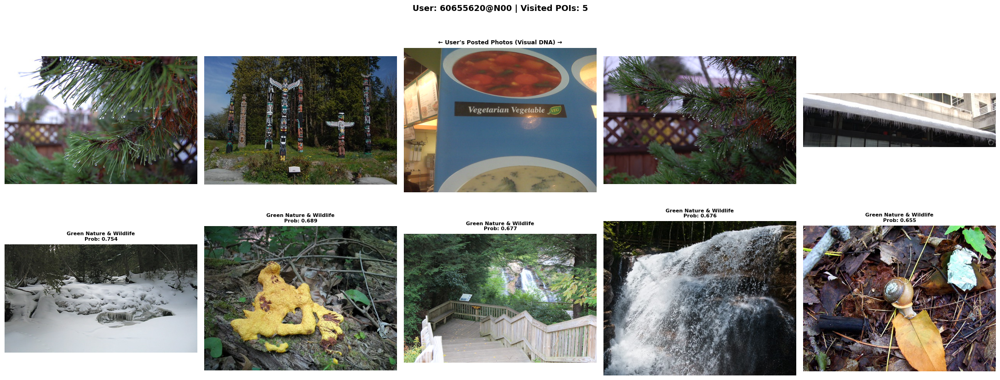

✓ User 60655620@N00 plotted.



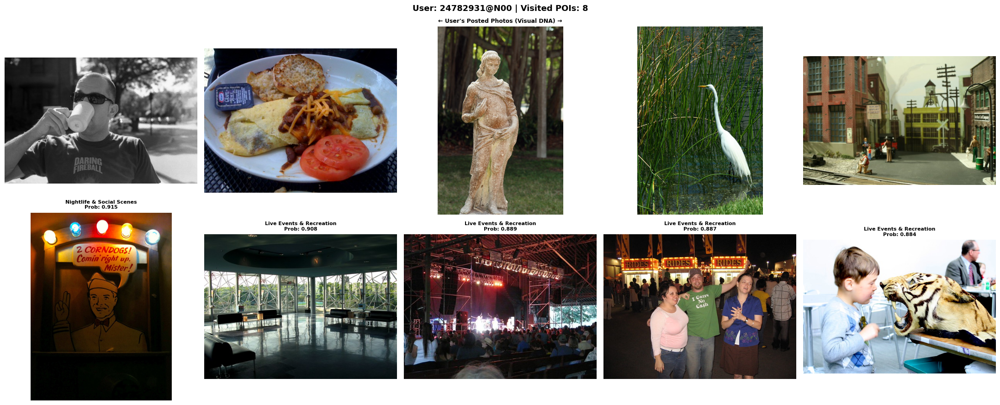

✓ User 24782931@N00 plotted.



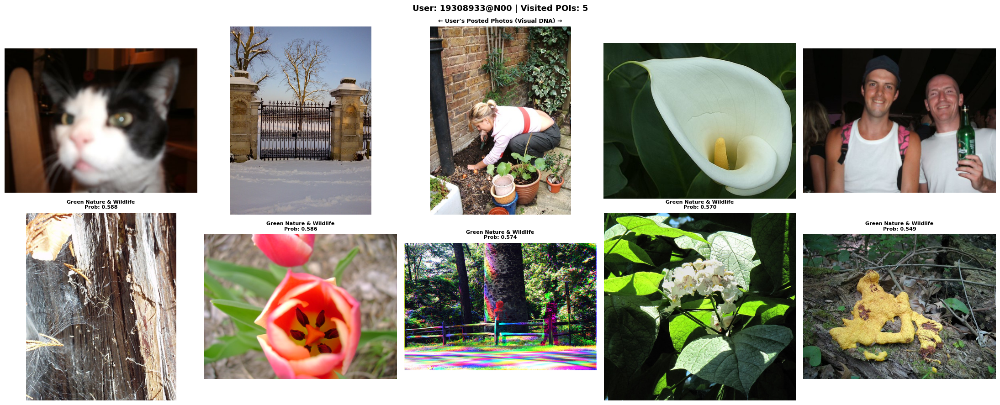

✓ User 19308933@N00 plotted.



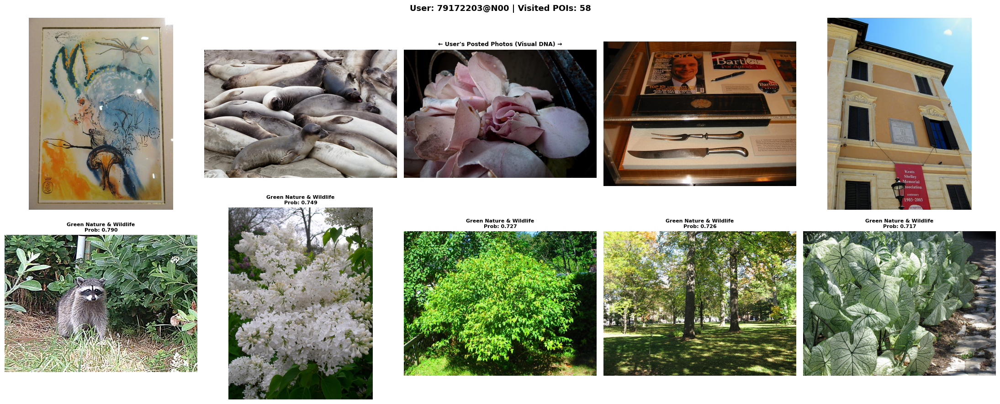

✓ User 79172203@N00 plotted.



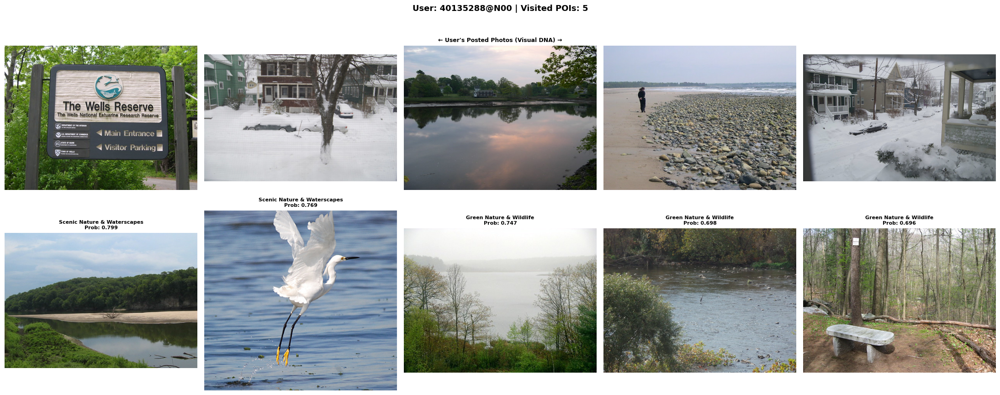

✓ User 40135288@N00 plotted.



In [12]:
%matplotlib inline
from urllib.parse import unquote_plus
from PIL import Image
from io import BytesIO
import requests

def fetch_image(url, timeout=5):
    try:
        r = requests.get(url, timeout=timeout)
        return Image.open(BytesIO(r.content)).convert('RGB')
    except:
        return None

df_indexed  = df.set_index('photoid')

# Build POI → sample photo URL lookup
print("Building POI → photo URL lookup...")
poi_to_pids = {}
for i, pid in enumerate(filtered_pids):
    poi = filtered_pois[i]
    poi_to_pids.setdefault(poi, []).append(pid)

def get_poi_image(poi_id):
    pids = poi_to_pids.get(poi_id, [])
    for pid in pids[:10]:
        if int(pid) not in df_indexed.index: continue
        url = unquote_plus(str(df_indexed.loc[int(pid)]['downloadurl']))
        img = fetch_image(url)
        if img: return img
    return None

# Pick 5 random eval users
sample_uids = np.random.choice(eval_uids, 5, replace=False)

for uid in sample_uids:
    u_idx    = user_id_to_idx[uid]
    user_emb = user_embeddings[u_idx]
    visited  = uid_to_visited_pois.get(uid, set())

    # --- User's posted images (Visual DNA) ---
    user_pids = [
        pid for pid in filtered_pids
        if pid_to_uid.get(int(pid)) == uid
    ]
    np.random.shuffle(user_pids)

    user_images = []
    for pid in user_pids:
        if int(pid) not in df_indexed.index: continue
        url = unquote_plus(str(df_indexed.loc[int(pid)]['downloadurl']))
        img = fetch_image(url)
        if img: user_images.append(img)
        if len(user_images) == 5: break

    # --- Top-10 recommended POIs ---
    # Use candidate retrieval for speed
    user_mem      = user_emb[256:]
    poi_mems      = np.array([poi_mem_dict.get(p, np.zeros(6)) for p in poi_ids])
    aes_scores    = poi_mems @ user_mem
    candidate_idx = np.argsort(aes_scores)[::-1][:CANDIDATE_POOL]

    candidate_poi_embs = torch.tensor(
        poi_embeddings[candidate_idx], dtype=torch.float32
    )
    u_tensor = torch.tensor(user_emb, dtype=torch.float32).unsqueeze(0)

    scores = []
    with torch.no_grad():
        for i in range(0, len(candidate_idx), BATCH_SIZE):
            batch_poi  = candidate_poi_embs[i:i+BATCH_SIZE].to(DEVICE)
            batch_user = u_tensor.expand(len(batch_poi), -1).to(DEVICE)
            scores.append(model(batch_user, batch_poi).cpu().numpy())
    scores = np.concatenate(scores)

    # Rank and get top 5
    top5_local  = np.argsort(scores)[::-1][:5]
    top5_pois   = poi_ids[candidate_idx[top5_local]]
    top5_scores = scores[top5_local]
    top5_labels = [poi_label_dict.get(p, "Unknown") for p in top5_pois]

    # Fetch recommended POI images
    rec_images = [get_poi_image(p) for p in top5_pois]

    # --- Plot ---
    fig, axes = plt.subplots(2, 5, figsize=(22, 9))
    fig.suptitle(
        f"User: {uid} | Visited POIs: {len(visited)}",
        fontsize=13, fontweight='bold'
    )

    # Row 1: User's posted photos
    for i in range(5):
        ax = axes[0, i]
        if i < len(user_images):
            ax.imshow(user_images[i])
        else:
            ax.set_facecolor('#eeeeee')
        if i == 2:
            ax.set_title("← User's Posted Photos (Visual DNA) →",
                        fontsize=9, fontweight='bold')
        ax.axis('off')

    # Row 2: Recommended POI images
    for i in range(5):
        ax = axes[1, i]
        if rec_images[i] is not None:
            ax.imshow(rec_images[i])
        else:
            ax.set_facecolor('#eeeeee')
            ax.text(0.5, 0.5, "No Image", ha='center', va='center',
                   transform=ax.transAxes, fontsize=9)
        ax.set_title(
            f"{top5_labels[i]}\nProb: {top5_scores[i]:.3f}",
            fontsize=8, fontweight='bold',
            color='green' if top5_pois[i] in visited else 'black'
        )
        ax.axis('off')

    # Row labels
    axes[0, 0].set_ylabel("User Photos", fontsize=10, fontweight='bold')
    axes[1, 0].set_ylabel("Recommended", fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()
    print(f"✓ User {uid} plotted.\n")